Tutorial: static analysis with inertia relief
===

A structure without supports, e.g. a launch vehicle or a spacecraft in flight,
can move as a rigid body: its stiffness matrix is singular and the linear
static solution cannot be applied as it stands. When the loads are not
balanced, the free structure accelerates, and inertia relief balances the
loads with the d'Alembert (inertia) forces of this rigid-body acceleration.
The displacements are then computed relative to a statically determinate
reference support, whose reactions vanish.

The analysis is done by `pyfe3d.solver.inertia_relief`, from the assembled
stiffness matrix `KC0` and the mass matrix `M` of the elements' `update_M`,
see the user guide page [Inertia relief](inertia_relief.rst). This notebook
verifies it in four cases:

1. three nodes joined by two springs, a singular system of rank 2, with
   balanced and unbalanced loads, a fictitious support and inertia relief,
   derived symbolically and solved with pyfe3d;
2. a chain of springs and point masses under unbalanced loads, with two
   reference supports;
3. a free-free beam of 10 `BeamC` elements under a balanced load set, its own
   weight balanced by two point loads and opposite axial end forces;
4. a free-free beam and a free-free bar under an end force, against
   closed-form solutions derived and checked with SymPy below.

The references are:

- Barnett, A. R., Widrick, T. W., Ludwiczak, D. R., *Closed-Form Static
  Analysis with Inertia Relief and Displacement-Dependent Loads Using a
  MSC/NASTRAN DMAP Alter*, NASA TM-106836, NASA Lewis Research Center,
  Cleveland, OH, 1995,
  [ntrs.nasa.gov/citations/19950013233](https://ntrs.nasa.gov/citations/19950013233):
  p. 2, the quasistatic flight phases and MSC/NASTRAN Solution 91; p. 6,
  Eqs. (16)-(22), the rigid-body transformation and accelerations; p. 7,
  Eqs. (23) and (24), the displacements relative to the reference support;
- Bathe, K. J., *Finite Element Procedures*, 2nd ed., K. J. Bathe,
  Watertown, MA, 2014: Sec. 4.2.2, Eqs. (4.42)-(4.45), the partition into
  unknown and prescribed displacements and the reactions; Sec. 8.2.5,
  pp. 726-727, the stiffness matrix of an unrestrained system is positive
  semi-definite, with one zero eigenvalue per rigid-body mode;
- Farhat, C., Géradin, M., On the general solution by a direct method of a
  large-scale singular system of linear equations: application to the
  analysis of floating structures, *International Journal for Numerical
  Methods in Engineering*, 41(4), 675-696, 1998,
  [doi:10.1002/(SICI)1097-0207(19980228)41:4&lt;675::AID-NME305&gt;3.0.CO;2-8](https://doi.org/10.1002/%28SICI%291097-0207%2819980228%2941%3A4%3C675%3A%3AAID-NME305%3E3.0.CO%3B2-8),
  for the null space of large sparse singular stiffness matrices;
- Cavaliere, F., Zlotnik, S., Sevilla, R., Larráyoz, X., Díez, P.,
  Nonintrusive reduced order model for parametric solutions of inertia
  relief problems, *International Journal for Numerical Methods in
  Engineering*, 122(16), 4270-4291, 2021,
  [doi:10.1002/nme.6702](https://doi.org/10.1002/nme.6702), for inertia
  relief in general.

The models and the same checks are in `tests/test_inertia_relief.py`, from
which the model builders are imported below.

The procedure in pyfe3d notation
---

The degrees of freedom are partitioned as in the linear static analysis of
pyfe3d, see the overview: `bu` selects the free degrees of freedom, set $u$,
and `bk` the constrained ones, set $k$, with the prescribed values `uk`. The
reference degrees of freedom of inertia relief, the r-set of Barnett et al.
(1995, p. 6), belong here to $k$, and the remaining ones, their l-set, to
$u$. In inertia relief,
`bk` contains the reference degrees of freedom `bref`, with `uk = 0`, plus any
degree of freedom that the model itself constrains (`bfix` below, e.g. the
rollers of a model along a line).

The $n_r$ rigid-body modes are the columns of $\boldsymbol{\Phi}$,
$\boldsymbol{K}_{C0} \boldsymbol{\Phi} = \boldsymbol{0}$. A static solution
$\boldsymbol{K}_{C0} \boldsymbol{u} = \boldsymbol{F}_{ext}$ exists only when
$\boldsymbol{\Phi}^\top \boldsymbol{F}_{ext} = \boldsymbol{0}$, i.e. when the
resultant forces and moments vanish. With a statically determinate reference
support, unit displacements at the reference degrees of freedom,
$\boldsymbol{\Phi}_k = \boldsymbol{I}$, give the rigid-body modes from the
stiffness matrix itself (Barnett et al. 1995, p. 6, Eq. (19)):

$$
\boldsymbol{\Phi} = \begin{bmatrix} \boldsymbol{\Phi}_u \\ \boldsymbol{\Phi}_k \end{bmatrix}
= \begin{bmatrix} -\boldsymbol{K}_{{C0}_{uu}}^{-1} \boldsymbol{K}_{{C0}_{uk}} \\ \boldsymbol{I} \end{bmatrix}
$$

The structure deforms elastically and accelerates as a rigid body,
$\ddot{\boldsymbol{u}} = \boldsymbol{\Phi} \ddot{\boldsymbol{\alpha}}$.
Premultiplying $\boldsymbol{M} \ddot{\boldsymbol{u}} + \boldsymbol{K}_{C0}
\boldsymbol{u} = \boldsymbol{F}_{ext}$ by $\boldsymbol{\Phi}^\top$, with
$\boldsymbol{\Phi}^\top \boldsymbol{K}_{C0} = \boldsymbol{0}$, gives the
rigid-body accelerations (Barnett et al. 1995, p. 6, Eqs. (21) and (22)):

$$
\boldsymbol{\Phi}^\top \boldsymbol{M} \boldsymbol{\Phi} \, \ddot{\boldsymbol{\alpha}} = \boldsymbol{\Phi}^\top \boldsymbol{F}_{ext}
$$

The d'Alembert forces $\boldsymbol{F}_I = -\boldsymbol{M} \boldsymbol{\Phi}
\ddot{\boldsymbol{\alpha}}$ balance the external loads,
$\boldsymbol{\Phi}^\top (\boldsymbol{F}_{ext} + \boldsymbol{F}_I) =
\boldsymbol{0}$, and the displacements relative to the reference support are
(Barnett et al. 1995, p. 7, Eqs. (23) and (24)):

$$
\boldsymbol{K}_{{C0}_{uu}} \boldsymbol{u}_u = \boldsymbol{F}_{{ext}_u} - \boldsymbol{M}_u \boldsymbol{\Phi} \ddot{\boldsymbol{\alpha}}, \qquad \boldsymbol{u}_k = \boldsymbol{0}
$$

The reactions of the reference support are the residual at the reference
degrees of freedom, $\boldsymbol{R}_k = (\boldsymbol{K}_{C0} \boldsymbol{u} -
\boldsymbol{F}_{ext} - \boldsymbol{F}_I)_k$, as in Bathe (2014), Eq. (4.45),
or $\boldsymbol{F}_{{int}_k} - \boldsymbol{f}_k$ in the overview of pyfe3d.
Since $\boldsymbol{R}_u = \boldsymbol{0}$ and $\boldsymbol{\Phi}^\top
\boldsymbol{K}_{C0} = \boldsymbol{0}$, premultiplying the residual by
$\boldsymbol{\Phi}^\top$ gives $\boldsymbol{\Phi}_k^\top \boldsymbol{R}_k =
-\boldsymbol{\Phi}^\top (\boldsymbol{F}_{ext} + \boldsymbol{F}_I) =
\boldsymbol{0}$, hence $\boldsymbol{R}_k = \boldsymbol{0}$: the reference
support carries no load.

**Choice of the reference support.** Any set of $n_r$ degrees of freedom whose
rows $\boldsymbol{\Phi}_k$ form a non-singular matrix, i.e. a statically
determinate support, can be chosen: it suppresses the rigid-body modes
without restraining any deformation. The displacements are measured relative
to it, and so they change with the choice by a rigid-body motion
$\boldsymbol{\Phi} \boldsymbol{\alpha}$, whereas the strains and internal
forces do not. A support with more degrees of freedom than $n_r$ is
statically indeterminate and would carry reactions; one that does not
suppress all the rigid-body modes leaves $\boldsymbol{K}_{{C0}_{uu}}$
singular.

These steps are implemented by `pyfe3d.solver.inertia_relief`, which also
checks that the reference support is statically determinate. Its argument
`bfix` holds the degrees of freedom constrained by the model itself, which
are excluded from
$\boldsymbol{\Phi}$.

The small function below collects its results in a dictionary, with the
d'Alembert forces $\boldsymbol{F}_I$, for the printouts of the cases.

In [1]:
import os
import sys
sys.path.insert(0, os.path.join('..', '..', 'tests'))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.sparse import csc_matrix
from scipy.sparse.linalg import spsolve

from pyfe3d import DOF
from test_inertia_relief import (spring_chain, point_masses, spring_forces,
                                 beam_prop, beam_model, geometric_rigid_modes,
                                 beam_end_forces, reference_dofs, chain_data)


from pyfe3d.solver import inertia_relief


def run_inertia_relief(KC0, M, fext, bref, bfix=None):
    """Results of pyfe3d.solver.inertia_relief, with the d'Alembert forces"""
    u, acc, Phi, R = inertia_relief(KC0, M, fext, bref, bfix,
                                    return_reactions=True)
    finertia = -(M @ (Phi @ acc))         # d'Alembert (inertia) forces
    bk = bref if bfix is None else bref | bfix
    return dict(u=u, acc=acc, Phi=Phi, R=R, finertia=finertia,
                ftot=fext + finertia, bu=~bk)

Case 1: three nodes joined by two springs
---

Three nodes along $x$, a spring $k_1$ between the nodes 1 and 2 and a spring
$k_2$ between the nodes 2 and 3, the point masses $m_1$, $m_2$, $m_3$ and the
forces $F_1$, $F_2$, $F_3$, all able to move only along $x$. The linear static
system

$$
\begin{bmatrix} k_1 & -k_1 & 0 \\ -k_1 & k_1 + k_2 & -k_2 \\ 0 & -k_2 & k_2 \end{bmatrix}
\begin{Bmatrix} u_1 \\ u_2 \\ u_3 \end{Bmatrix}
= \begin{Bmatrix} F_1 \\ F_2 \\ F_3 \end{Bmatrix}
$$

has a stiffness matrix whose rows add to zero, of rank 2, with the rigid
translation $\boldsymbol{\phi} = \{1, 1, 1\}^\top$ in its null space,
$\boldsymbol{K}_{C0} \boldsymbol{\phi} = \boldsymbol{0}$, so its inverse does
not exist. Adding the three rows, i.e. premultiplying by
$\boldsymbol{\phi}^\top$, shows that a solution exists only for balanced
loads:

$$
\boldsymbol{\phi}^\top \boldsymbol{F}_{ext} = F_1 + F_2 + F_3 = 0
$$

**Balanced loads.** Rows 1 and 3 give $k_1 (u_2 - u_1) = -F_1$ and $k_2 (u_3 -
u_2) = F_3$, and row 2 is minus their sum. They fix the elongations of the
springs but not the position of the system:

$$
\boldsymbol{u} = \begin{Bmatrix} 0 \\ -F_1/k_1 \\ -F_1/k_1 + F_3/k_2 \end{Bmatrix}
+ \alpha \begin{Bmatrix} 1 \\ 1 \\ 1 \end{Bmatrix}
$$

with an arbitrary amplitude $\alpha$ of the rigid translation, which does not
change the spring forces.

**Fictitious support.** Prescribing $\bar{u}_1 = 0$, a statically determinate
support (in pyfe3d notation, `bref`, part of `bk`, is the $x$ degree of
freedom of node 1, and `bu` those of the nodes 2 and 3), the partition gives

$$
\boldsymbol{K}_{{C0}_{uu}} = \begin{bmatrix} k_1 + k_2 & -k_2 \\ -k_2 & k_2 \end{bmatrix},
\qquad \det \boldsymbol{K}_{{C0}_{uu}} = k_1 k_2 > 0,
\qquad \boldsymbol{K}_{{C0}_{uk}} = \begin{Bmatrix} -k_1 \\ 0 \end{Bmatrix}
$$

and $\boldsymbol{K}_{{C0}_{uu}} \{u_2, u_3\}^\top = \{F_2, F_3\}^\top$, i.e.
$u_2 = (F_2 + F_3)/k_1$ and $u_3 = u_2 + F_3/k_2$, with the reaction $R_1 =
-k_1 u_2 - F_1 = -(F_1 + F_2 + F_3)$. For balanced loads, $u_2 = -F_1/k_1$,
the solution above with $\alpha = 0$, and $R_1 = 0$: the support does not
change the solution. For unbalanced loads, e.g. $F_1 = F_2 = 0$ and $F_3 =
F$, the support carries the reaction $R_1 = -F$ and the spring $k_1$ the
full force $F$, which is not the state of the free system: the fictitious
support alone gives unrealistic reactions and internal forces.

**Inertia relief.** The free system accelerates as a rigid body, and the
loads are balanced by the d'Alembert forces of this acceleration. With the
same support, now the reference support, the rigid-body mode follows from
the stiffness matrix, $\boldsymbol{\Phi}_u = -\boldsymbol{K}_{{C0}_{uu}}^{-1}
\boldsymbol{K}_{{C0}_{uk}} = \{1, 1\}^\top$, i.e. $\boldsymbol{\Phi} =
\boldsymbol{\phi}$, and, with $\boldsymbol{M} = \mathrm{diag}(m_1, m_2,
m_3)$, $\boldsymbol{\Phi}^\top \boldsymbol{M} \boldsymbol{\Phi} = m_1 + m_2 +
m_3$, so

$$
\ddot{\alpha} = \frac{F_1 + F_2 + F_3}{m_1 + m_2 + m_3}
$$

The two free equations are

$$
\begin{bmatrix} k_1 + k_2 & -k_2 \\ -k_2 & k_2 \end{bmatrix}
\begin{Bmatrix} u_2 \\ u_3 \end{Bmatrix}
= \begin{Bmatrix} F_2 - m_2 \ddot{\alpha} \\ F_3 - m_3 \ddot{\alpha} \end{Bmatrix}
$$

whose solution, adding the two rows for the first, is

$$
u_2 = \frac{F_2 + F_3 - (m_2 + m_3) \ddot{\alpha}}{k_1}, \qquad
u_3 = u_2 + \frac{F_3 - m_3 \ddot{\alpha}}{k_2}
$$

For $F_1 = F_2 = 0$ and $F_3 = F$, the spring forces are $k_1 u_2 = m_1
\ddot{\alpha}$ and $k_2 (u_3 - u_2) = (m_1 + m_2) \ddot{\alpha}$, the forces
that accelerate the masses on the left of each spring, and the reaction of
the reference support is $R_1 = -k_1 u_2 - (F_1 - m_1 \ddot{\alpha}) = 0$.
For balanced loads, $\ddot{\alpha} = 0$ and the fictitious support is
recovered.

**Reference support at node 3**, $\bar{u}_3 = 0$: the solution changes by
the rigid translation $-u_3 \boldsymbol{\phi}$, and the spring forces are
unchanged.

SymPy verifies these expressions:

In [2]:
k1, k2, m1, m2, m3, F1, F2, F3, F = sp.symbols('k_1 k_2 m_1 m_2 m_3 F_1 F_2 F_3 F')
K3 = sp.Matrix([[k1, -k1, 0], [-k1, k1 + k2, -k2], [0, -k2, k2]])
M3s = sp.diag(m1, m2, m3)
F3v = sp.Matrix([F1, F2, F3])
print('rank:', K3.rank(), ', null space:', [list(v) for v in K3.nullspace()])
assert K3.rank() == 2 and list(K3.nullspace()[0]) == [1, 1, 1]
assert list(K3*sp.ones(3, 1)) == [0, 0, 0]

# solvability: adding the rows gives F1 + F2 + F3 = 0
u1s, u2s, u3s, alpha = sp.symbols('u_1 u_2 u_3 alpha')
us = sp.Matrix([u1s, u2s, u3s])
assert sp.expand((sp.ones(1, 3)*(K3*us))[0]) == 0
# balanced loads, F2 = -F1 - F3: u = {0, -F1/k1, -F1/k1 + F3/k2} + alpha phi
bal = {F2: -F1 - F3}
u_bal = sp.Matrix([0, -F1/k1, -F1/k1 + F3/k2]) + alpha*sp.ones(3, 1)
assert sp.simplify(K3*u_bal - F3v.subs(bal)) == sp.zeros(3, 1)
print('balanced loads: u =', list(u_bal))

# fictitious support u1 = 0 without inertia forces: R1 = -(F1 + F2 + F3)
u23 = K3[1:, 1:].inv()*F3v[1:, :]
R1_fict = sp.simplify((K3[0, 1:]*u23)[0] - F1)
print('fictitious support: u2 =', sp.factor(u23[0]), ', u3 =', sp.factor(u23[1]),
      ', R1 =', R1_fict)
assert sp.simplify(u23[0] - (F2 + F3)/k1) == 0
assert sp.simplify(u23[1] - (F2 + F3)/k1 - F3/k2) == 0
assert sp.simplify(R1_fict + F1 + F2 + F3) == 0
assert sp.simplify(R1_fict.subs(bal)) == 0
assert sp.simplify(u23.subs(bal) - u_bal[1:, :].subs(alpha, 0)) == sp.zeros(2, 1)

# reference support at node 1: k = {1}, u = {2, 3}
Kuu = K3[1:, 1:]
Kuk = K3[1:, :1]
print('K_uu =', Kuu.tolist(), ', det =', sp.factor(Kuu.det()), ', K_uk =', list(Kuk))
assert sp.simplify(Kuu.det() - k1*k2) == 0
Phi3 = sp.Matrix.vstack(sp.eye(1), sp.simplify(-Kuu.inv()*Kuk))
assert list(Phi3) == [1, 1, 1]
add3 = sp.simplify(((Phi3.T*M3s*Phi3).inv()*(Phi3.T*F3v))[0])
assert sp.simplify(add3 - (F1 + F2 + F3)/(m1 + m2 + m3)) == 0
Ftot3 = F3v - M3s*Phi3*add3
assert sp.simplify((Phi3.T*Ftot3)[0]) == 0
uu = sp.simplify(Kuu.inv()*Ftot3[1:, :])
u2_cf = (F2 + F3 - (m2 + m3)*add3)/k1
u3_cf = u2_cf + (F3 - m3*add3)/k2
assert sp.simplify(uu[0] - u2_cf) == 0 and sp.simplify(uu[1] - u3_cf) == 0
print('alpha_dd =', add3)
print('u2 =', sp.factor(uu[0]), '\nu3 =', sp.factor(uu[1]))

# F1 = F2 = 0, F3 = F: spring forces and reaction
sub = {F1: 0, F2: 0, F3: F}
a = add3.subs(sub)
N1, N2 = k1*uu[0].subs(sub), k2*(uu[1] - uu[0]).subs(sub)
R1 = -k1*uu[0].subs(sub) - (0 - m1*a)
assert sp.simplify(N1 - m1*a) == 0 and sp.simplify(N2 - (m1 + m2)*a) == 0
assert sp.simplify(R1) == 0
print('F3 = F: k1 u2 =', sp.factor(N1), ', k2 (u3 - u2) =', sp.factor(N2), ', R1 =', sp.simplify(R1))

# reference support at node 3: k = {3}, u = {1, 2}
u_n1 = sp.Matrix([0, uu[0], uu[1]])
Kuu3 = K3[:2, :2]
u12 = sp.simplify(Kuu3.inv()*Ftot3[:2, :])
u_n3 = sp.Matrix([u12[0], u12[1], 0])
assert sp.simplify(u_n3 - (u_n1 - uu[1]*sp.ones(3, 1))) == sp.zeros(3, 1)
print('reference at node 3: u = u(reference at node 1) - u3 phi')

rank: 2 , null space: [[1, 1, 1]]
balanced loads: u = [alpha, -F_1/k_1 + alpha, -F_1/k_1 + F_3/k_2 + alpha]
fictitious support: u2 = (F_2 + F_3)/k_1 , u3 = (F_2*k_2 + F_3*k_1 + F_3*k_2)/(k_1*k_2) , R1 = -F_1 - F_2 - F_3
K_uu = [[k_1 + k_2, -k_2], [-k_2, k_2]] , det = k_1*k_2 , K_uk = [-k_1, 0]


alpha_dd = (F_1 + F_2 + F_3)/(m_1 + m_2 + m_3)
u2 = -(F_1*m_2 + F_1*m_3 - F_2*m_1 - F_3*m_1)/(k_1*(m_1 + m_2 + m_3)) 
u3 = -(F_1*k_1*m_3 + F_1*k_2*m_2 + F_1*k_2*m_3 + F_2*k_1*m_3 - F_2*k_2*m_1 - F_3*k_1*m_1 - F_3*k_1*m_2 - F_3*k_2*m_1)/(k_1*k_2*(m_1 + m_2 + m_3))
F3 = F: k1 u2 = F*m_1/(m_1 + m_2 + m_3) , k2 (u3 - u2) = F*(m_1 + m_2)/(m_1 + m_2 + m_3) , R1 = 0
reference at node 3: u = u(reference at node 1) - u3 phi


The same model with pyfe3d: two `Spring` elements with `kxe` $= k_1$ and $k_2$,
the other degrees of freedom constrained (`bfix`), the point masses in a
diagonal $\boldsymbol{M}$, with $k_1 = 2000$ N/m, $k_2 = 500$ N/m, $m_1 = 1$
kg, $m_2 = 2$ kg, $m_3 = 3$ kg. First the fictitious support alone, `bref` without inertia forces, solved
as a linear static analysis: for the balanced loads $F_1 = -5$ N, $F_2 = 1$
N, $F_3 = 4$ N it gives $u_2 = 2.5$ mm, $u_3 = 10.5$ mm and $R_1 = 0$; for
$F_1 = F_2 = 0$, $F_3 = F = 12$ N, $u_2 = 6$ mm, $u_3 = 30$ mm and $R_1 =
-12$ N. Then inertia relief, with two load sets: $F_1 = F_2 = 0$, $F_3 = F =
12$ N, for which $\ddot{\alpha} = 2$ m/s$^2$, $u_2 = 1$ mm and $u_3 =
13$ mm; and $F_1 = 3$ N, $F_2 = -4$ N, $F_3 = 10$ N. The rank and the null
space of the $3 \times 3$ stiffness matrix of the $x$ degrees of freedom are
computed numerically.

In [3]:
from scipy.linalg import null_space

k1_, k2_ = 2000., 500.
mst = np.array([1., 2., 3.])
KCt, bfixt, springst = spring_chain([k1_, k2_])
Mt = point_masses(mst)
Nt = KCt.shape[0]
Kx = KCt.toarray()[0::DOF, 0::DOF]
print('K (x dofs) =\n', Kx)
print('rank =', np.linalg.matrix_rank(Kx), ', row sums =', Kx.sum(axis=1))
ns = null_space(Kx)[:, 0]
print('null space, normalised to node 1:', ns/ns[0])
assert np.linalg.matrix_rank(Kx) == 2
assert np.allclose(ns/ns[0], 1.)

# fictitious support u1 = 0 alone, without inertia forces
bref1 = np.zeros(Nt, dtype=bool)
bref1[0] = True
bu1 = ~(bref1 | bfixt)
for Fs in ([-5., 1., 4.], [0., 0., 12.]):
    Fs = np.array(Fs)
    fext = np.zeros(Nt)
    fext[0::DOF] = Fs
    u = np.zeros(Nt)
    u[bu1] = spsolve(csc_matrix(KCt)[bu1, :][:, bu1], fext[bu1])
    R1 = (KCt @ u - fext)[0]
    u2 = (Fs[1] + Fs[2])/k1_
    u3 = u2 + Fs[2]/k2_
    print('fictitious support, F = %s N: u = %s mm, R1 = %.1e N (closed form %.1e N)'
          % (Fs, np.round(1e3*u[0::DOF], 6), R1, -Fs.sum()))
    assert np.allclose(u[0::DOF], [0., u2, u3], rtol=1e-12, atol=1e-16)
    assert np.isclose(R1, -Fs.sum(), rtol=1e-12, atol=1e-13*abs(Fs).max())
    if Fs.sum() == 0:
        # the balanced general solution with alpha = 0
        assert np.allclose(u[0::DOF], [0., -Fs[0]/k1_, -Fs[0]/k1_ + Fs[2]/k2_],
                           rtol=1e-12)

for Fs in ([0., 0., 12.], [3., -4., 10.]):
    Fs = np.array(Fs)
    fext = np.zeros(Nt)
    fext[0::DOF] = Fs
    acc = Fs.sum()/mst.sum()
    u2 = (Fs[1] + Fs[2] - (mst[1] + mst[2])*acc)/k1_
    u3 = u2 + (Fs[2] - mst[2]*acc)/k2_
    print('\nF =', Fs, 'N, closed form: alpha_dd = %.4f m/s2, u2 = %.4f mm, u3 = %.4f mm'
          % (acc, 1e3*u2, 1e3*u3))
    out = {}
    for r in (0, 2):
        bref = np.zeros(Nt, dtype=bool)
        bref[DOF*r] = True
        o = run_inertia_relief(KCt, Mt, fext, bref, bfixt)
        out[r] = o
        Nsp = spring_forces(springst, o['u'])
        print('  reference node %d: Phi = %s, alpha_dd = %.4f, u = %s mm, spring forces = %s N, '
              'R = %.1e N, Phi^T F_tot = %.1e'
              % (r + 1, o['Phi'][0::DOF, 0], o['acc'][0], np.round(1e3*o['u'][0::DOF], 6),
                 np.round(Nsp, 6), o['R'][DOF*r], (o['Phi'].T @ o['ftot'])[0]))
        assert np.allclose(o['Phi'][0::DOF, 0], 1., rtol=1e-14)
        assert np.isclose(o['acc'][0], acc, rtol=1e-14)
        assert abs(o['R'][DOF*r]) < 1e-13*abs(Fs).max()
        assert abs(o['Phi'].T @ o['ftot']).max() < 1e-13*abs(Fs).max()
        assert np.allclose(Nsp, [k1_*u2, k2_*(u3 - u2)], rtol=1e-12)
    assert np.allclose(out[0]['u'][0::DOF], [0., u2, u3], rtol=1e-12, atol=1e-16)
    assert np.allclose(out[2]['u'][0::DOF], np.array([0., u2, u3]) - u3, rtol=1e-12, atol=1e-16)
    if Fs[0] == Fs[1] == 0:
        assert np.isclose(k1_*u2, mst[0]*acc, rtol=1e-12)
        assert np.isclose(k2_*(u3 - u2), (mst[0] + mst[1])*acc, rtol=1e-12)

K (x dofs) =
 [[ 2000. -2000.     0.]
 [-2000.  2500.  -500.]
 [    0.  -500.   500.]]
rank = 2 , row sums = [0. 0. 0.]
null space, normalised to node 1: [1. 1. 1.]
fictitious support, F = [-5.  1.  4.] N: u = [ 0.   2.5 10.5] mm, R1 = 0.0e+00 N (closed form -0.0e+00 N)
fictitious support, F = [ 0.  0. 12.] N: u = [ 0.  6. 30.] mm, R1 = -1.2e+01 N (closed form -1.2e+01 N)

F = [ 0.  0. 12.] N, closed form: alpha_dd = 2.0000 m/s2, u2 = 1.0000 mm, u3 = 13.0000 mm
  reference node 1: Phi = [1. 1. 1.], alpha_dd = 2.0000, u = [ 0.  1. 13.] mm, spring forces = [2. 6.] N, R = 0.0e+00 N, Phi^T F_tot = 0.0e+00
  reference node 3: Phi = [1. 1. 1.], alpha_dd = 2.0000, u = [-13. -12.   0.] mm, spring forces = [2. 6.] N, R = 8.9e-16 N, Phi^T F_tot = 0.0e+00

F = [ 3. -4. 10.] N, closed form: alpha_dd = 1.5000 m/s2, u2 = -0.7500 mm, u3 = 10.2500 mm
  reference node 1: Phi = [1. 1. 1.], alpha_dd = 1.5000, u = [ 0.   -0.75 10.25] mm, spring forces = [-1.5  5.5] N, R = 0.0e+00 N, Phi^T F_tot = 0.0e+00


With the fictitious support alone, the balanced loads give the general
solution with $\alpha = 0$ and no reaction, whereas the unbalanced loads
give the reaction $-(F_1 + F_2 + F_3)$. With inertia relief, the rank, the
null space, $\boldsymbol{\Phi}$, $\ddot{\alpha}$, $u_2$, $u_3$
and the spring forces match the closed form, the reaction of the reference
support vanishes, and moving the reference support from node 1 to node 3
shifts every displacement by $-u_3$ without changing the spring forces.

Case 2: a chain of springs and point masses
---

Five point masses $m_i$ joined by four springs $k_j$ along $x$, free-free,
under unbalanced loads $F_i$. As in case 1, the rigid-body acceleration is
$\ddot{\alpha} = \sum_i F_i / \sum_i m_i$ and the inertia forces are
$-m_i \ddot{\alpha}$. Cutting the spring $j$, between the nodes $j$ and
$j + 1$ (numbered from 0), the equilibrium of the part to its right with the
inertia forces gives the spring force, positive in tension,

$$
N_j = \sum_{i > j} \left(F_i - m_i \ddot{\alpha}\right)
$$

and the displacements relative to the reference node $r$ follow from
$u_{j+1} - u_j = N_j / k_j$ with $u_r = 0$. Two reference supports are used,
node 0 and node 3; both are statically determinate (one degree of freedom
for the one rigid-body mode). The spring forces must be the same, and the
displacements must differ by a rigid translation.

In [4]:
ks, ms, Fc = chain_data()
print('k_j [N/m] =', ks, '\nm_i [kg]  =', ms, '\nF_i [N]   =', Fc)
KC0c, bfix_c, springs_c = spring_chain(ks)
Mc = point_masses(ms)
Nc = KC0c.shape[0]
fext_c = np.zeros(Nc)
fext_c[0::DOF] = Fc

acc_ref = Fc.sum()/ms.sum()
Nj_ref = np.array([(Fc[j+1:] - ms[j+1:]*acc_ref).sum() for j in range(len(ks))])
res = {}
for r in (0, 3):
    bref = np.zeros(Nc, dtype=bool)
    bref[DOF*r] = True
    out = run_inertia_relief(KC0c, Mc, fext_c, bref, bfix_c)
    res[r] = out
    u_ref = np.concatenate(([0.], np.cumsum(Nj_ref/ks)))
    u_ref -= u_ref[r]
    print('\nreference node %d' % r)
    print('  alpha_dd = %.6f m/s2 (closed form %.6f)' % (out['acc'][0], acc_ref))
    print('  inertia forces [N]    =', np.round(out['finertia'][0::DOF], 6))
    print('  Phi^T F_tot           = %.1e' % (out['Phi'].T @ out['ftot'])[0])
    print('  reaction R_r [N]      = %.1e' % out['R'][DOF*r])
    print('  spring forces FE  [N] =', np.round(spring_forces(springs_c, out['u']), 6))
    print('  closed form       [N] =', np.round(Nj_ref, 6))
    print('  u FE [mm]             =', np.round(1e3*out['u'][0::DOF], 6))
    print('  u closed form [mm]    =', np.round(1e3*u_ref, 6))
    assert np.isclose(out['acc'][0], acc_ref, rtol=1e-14)
    assert abs(out['R'][DOF*r]) < 1e-13*abs(Fc).max()
    assert abs(out['Phi'].T @ out['ftot']).max() < 1e-13*abs(Fc).max()
    assert np.allclose(spring_forces(springs_c, out['u']), Nj_ref, rtol=1e-12)
    assert np.allclose(out['u'][0::DOF], u_ref, rtol=1e-12, atol=1e-16)

diff = res[3]['u'][0::DOF] - res[0]['u'][0::DOF]
print('\nu(ref 3) - u(ref 0) [mm] =', np.round(1e3*diff, 6), '(a rigid translation)')
assert np.allclose(diff, diff[0], rtol=1e-12)

k_j [N/m] = [1000. 2000. 1500. 3000.] 
m_i [kg]  = [1.  2.  1.5 0.5 3. ] 
F_i [N]   = [ 0.  5. -2.  0. 12.]

reference node 0
  alpha_dd = 1.875000 m/s2 (closed form 1.875000)
  inertia forces [N]    = [-1.875  -3.75   -2.8125 -0.9375 -5.625 ]
  Phi^T F_tot           = 1.3e-15
  reaction R_r [N]      = -8.9e-16
  spring forces FE  [N] = [1.875  0.625  5.4375 6.375 ]
  closed form       [N] = [1.875  0.625  5.4375 6.375 ]
  u FE [mm]             = [0.     1.875  2.1875 5.8125 7.9375]
  u closed form [mm]    = [0.     1.875  2.1875 5.8125 7.9375]

reference node 3
  alpha_dd = 1.875000 m/s2 (closed form 1.875000)
  inertia forces [N]    = [-1.875  -3.75   -2.8125 -0.9375 -5.625 ]
  Phi^T F_tot           = 4.4e-16
  reaction R_r [N]      = 5.6e-16
  spring forces FE  [N] = [1.875  0.625  5.4375 6.375 ]
  closed form       [N] = [1.875  0.625  5.4375 6.375 ]
  u FE [mm]             = [-5.8125 -3.9375 -3.625   0.      2.125 ]
  u closed form [mm]    = [-5.8125 -3.9375 -3.625   0.      2.125

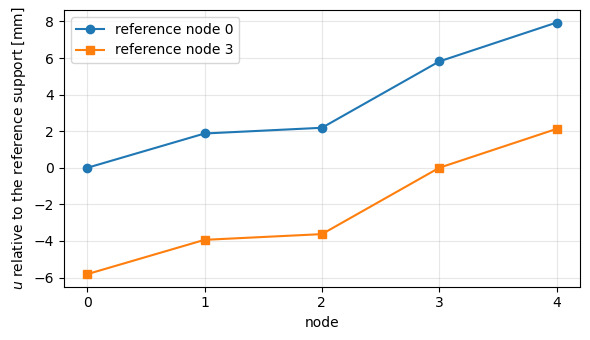

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
xn = np.arange(len(ms))
for r, marker in [(0, 'o'), (3, 's')]:
    ax.plot(xn, 1e3*res[r]['u'][0::DOF], marker=marker, label='reference node %d' % r)
ax.set_xlabel('node')
ax.set_ylabel('$u$ relative to the reference support [mm]')
ax.set_xticks(xn)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

The rigid-body acceleration, the inertia forces and the spring forces are
those of the closed form and do not depend on the reference node; the
displacements, measured from the reference node, differ by the rigid
translation $u_3 - u_0$ of the first solution.

Case 3: a free-free beam under a balanced load set
---

A steel beam of length $L = 2$ m along the global $x$ axis, rectangular
cross section of width $b = 0.02$ m along $y$ and height $h = 0.05$ m along
$z$, $E = 210$ GPa, $G = E/2.6$, $\rho = 7850$ kg/m$^3$, is modelled with 10
`BeamC` elements and the consistent mass matrix (`mtype=0`), with the rotary
inertia of the section. The element axes are the global axes. It has six
rigid-body modes and no support.

The loads are:

- its own weight, as the product of the mass matrix and the uniform
  acceleration field $-g$ along $z$, $\boldsymbol{F}_g = \boldsymbol{M}
  \boldsymbol{a}_g$, $g = 9.81$ m/s$^2$, whose resultant is $-W$ with $W = m L
  g$ and $m = \rho A$, applied at the centre of mass $x = L/2$;
- two upward point loads $W/2$ along $+z$ at the nodes $x = a = 0.4$ m and
  $x = L - a = 1.6$ m, symmetric about the centre of mass, such that the
  resultant force along $z$ and the resultant moment about $y$ vanish;
- opposite axial forces, $-P$ at $x = 0$ and $+P$ at $x = L$, $P = 1000$ N.

The load set is balanced in force and moment, so inertia relief must give
zero rigid-body accelerations and zero reactions of the reference support, to
round-off. Two statically determinate reference supports are used: the six
degrees of freedom of the first node (`'clamp'`), and $u, v, w, r_x$ of the
first node with $v, w$ of the last node (`'pin-roller'`).

In [6]:
L3, nel3, g, Pax, a3 = 2., 10, 9.81, 1000., 0.4
prop3 = beam_prop()                     # rotary inertia included
xs3, KC03, M3, beams3 = beam_model(L3, nel3, prop3, mtype=0)
N3 = KC03.shape[0]
m3 = prop3.intrho

agrav = np.zeros(N3)
agrav[2::DOF] = -g                      # uniform acceleration field -g along z
fgrav = M3 @ agrav                      # own weight, consistent nodal loads
W = -fgrav[2::DOF].sum()
fext3 = fgrav.copy()
for xa in (a3, L3 - a3):
    fext3[DOF*np.argmin(abs(xs3 - xa)) + 2] += W/2
fext3[0] -= Pax
fext3[DOF*nel3] += Pax
print('W from M a_g = %.6f N, m L g = %.6f N' % (W, m3*L3*g))
assert np.isclose(W, m3*L3*g, rtol=1e-13)

Phig = geometric_rigid_modes(xs3)      # translations and rotations about the origin
print('resultants of the external loads, Phi_geo^T F_ext =', Phig.T @ fext3)
assert abs(Phig.T @ fext3).max() < 1e-12*W

W from M a_g = 154.017000 N, m L g = 154.017000 N
resultants of the external loads, Phi_geo^T F_ext = [ 0.00000000e+00  0.00000000e+00  2.93098879e-14  0.00000000e+00
 -5.79536419e-14  0.00000000e+00]


The rigid-body modes computed from the stiffness matrix, $\boldsymbol{\Phi} =
[-\boldsymbol{K}_{{C0}_{uu}}^{-1} \boldsymbol{K}_{{C0}_{uk}}; \boldsymbol{I}]$,
satisfy $\boldsymbol{K}_{C0} \boldsymbol{\Phi} = \boldsymbol{0}$ and span the
same space as the geometric rigid-body modes, translations and rotations about
the origin: the least-squares fit $\boldsymbol{\Phi}_{geo} \boldsymbol{C} =
\boldsymbol{\Phi}$ has a zero residual. $\boldsymbol{\Phi}^\top \boldsymbol{M}
\boldsymbol{\Phi}$ is the $6 \times 6$ rigid-body mass matrix about the
reference node.

In [7]:
res3 = {}
for choice in ('clamp', 'pin-roller'):
    bref = reference_dofs(len(xs3), choice)
    out = run_inertia_relief(KC03, M3, fext3, bref)
    res3[choice] = out
    Phi = out['Phi']
    C = np.linalg.lstsq(Phig, Phi, rcond=None)[0]
    print('reference support: %s' % choice)
    print('  max |K_C0 Phi| / max |K_C0|   = %.1e' % (abs(KC03 @ Phi).max()/abs(KC03).max()))
    print('  residual of Phi_geo C = Phi   = %.1e' % abs(Phig @ C - Phi).max())
    print('  rigid-body accelerations      =', np.array2string(out['acc'], precision=2))
    print('  Phi^T F_tot                   =', np.array2string(Phi.T @ out['ftot'], precision=2))
    print('  reactions R_k                 =', np.array2string(out['R'][bref], precision=2))
    print('  max |R_u|                     = %.1e' % abs(out['R'][out['bu']]).max())
    assert abs(KC03 @ Phi).max() < 1e-6*abs(KC03).max()
    assert abs(Phig @ C - Phi).max() < 1e-10
    assert abs(out['acc'][:3]).max() < 1e-12*g
    assert abs(Phi.T @ out['ftot']).max() < 1e-10*W
    assert abs(out['R'][bref]).max() < 1e-10*W
print('\nPhi^T M Phi with the clamp at x = 0 (m L = %.4f kg, m L^3/3 = %.4f kg m2):'
      % (m3*L3, m3*L3**3/3))
print(np.array2string(res3['clamp']['Phi'].T @ (M3 @ res3['clamp']['Phi']), precision=4))

reference support: clamp
  max |K_C0 Phi| / max |K_C0|   = 1.1e-16
  residual of Phi_geo C = Phi   = 9.1e-14
  rigid-body accelerations      = [ 1.45e-14  0.00e+00 -5.21e-14  0.00e+00 -4.60e-14  0.00e+00]
  Phi^T F_tot                   = [ 2.27e-13  0.00e+00 -1.03e-14  0.00e+00  5.55e-15  0.00e+00]
  reactions R_k                 = [ 0.00e+00  0.00e+00 -6.75e-14  0.00e+00  4.76e-14  0.00e+00]
  max |R_u|                     = 1.2e-13
reference support: pin-roller
  max |K_C0 Phi| / max |K_C0|   = 1.1e-16
  residual of Phi_geo C = Phi   = 9.2e-14
  rigid-body accelerations      = [ 1.45e-14  0.00e+00 -7.32e-14  0.00e+00  0.00e+00  2.83e-14]
  Phi^T F_tot                   = [2.27e-13 0.00e+00 6.27e-15 0.00e+00 0.00e+00 6.86e-15]
  reactions R_k                 = [ 0.00e+00  0.00e+00 -8.53e-14  0.00e+00  0.00e+00 -4.17e-14]
  max |R_u|                     = 4.3e-13

Phi^T M Phi with the clamp at x = 0 (m L = 15.7000 kg, m L^3/3 = 20.9333 kg m2):
[[ 1.5700e+01  0.0000e+00  0.0000e+00  0.

The rigid-body accelerations, the reactions of both reference supports and
$\boldsymbol{\Phi}^\top \boldsymbol{F}_{tot}$ vanish to round-off: for a
balanced load set, inertia relief reduces to the fictitious support of the
singular static problem.

The internal forces follow from the end forces of each element, `finte` of
`update_probe_finte`, minus the element's own share of the distributed load,
$\boldsymbol{M}_e \boldsymbol{a}_g$ (the `beam_end_forces` function of the
test). Taking the bending moment $M(x)$ as the moment about $y$ at the first
node of each element, it is compared with the statics of the beam,

$$
M(x) = -\frac{m g x^2}{2} + \frac{W}{2} \langle x - a \rangle + \frac{W}{2} \langle x - (L - a) \rangle
$$

with $\langle x - a \rangle = \max(x - a, 0)$, and the axial force with $P$.

clamp      max |M_FE - M_statics| = 1.2e-13 N m, axial forces [N]: [1000.]
pin-roller max |M_FE - M_statics| = 1.3e-13 N m, axial forces [N]: [1000.]


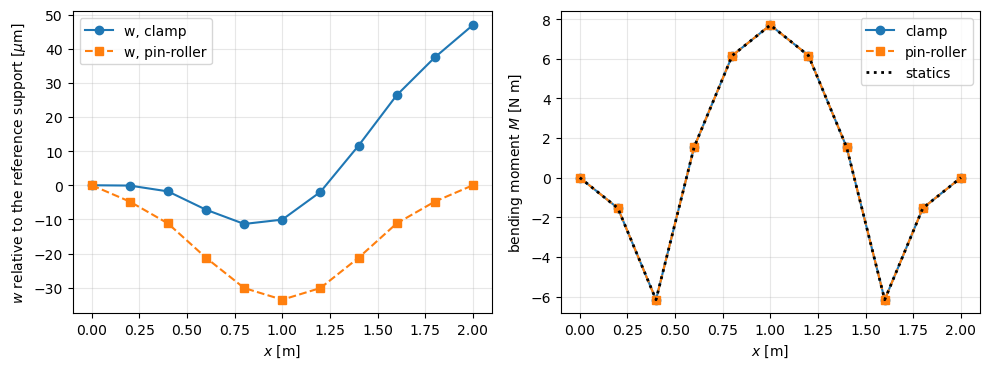

difference of the two solutions = rigid-body motion, residual 8.7e-19 m
axial elongation u(L) - u(0) = 9.5238e-06 m, P L/(E A) = 9.5238e-06 m


In [8]:
Mcf3 = (-m3*g*xs3**2/2 + W/2*np.clip(xs3 - a3, 0, None)
        + W/2*np.clip(xs3 - (L3 - a3), 0, None))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for choice, ls in [('clamp', '-o'), ('pin-roller', '--s')]:
    out = res3[choice]
    S = beam_end_forces(beams3, prop3, out['u'], M3, agrav)
    Mfe = np.append(S[:, 4], -S[-1, 10])
    print('%-10s max |M_FE - M_statics| = %.1e N m, axial forces [N]: %s'
          % (choice, abs(Mfe - Mcf3).max(), np.unique(np.round(S[:, 6], 9))))
    assert np.allclose(Mfe, Mcf3, atol=1e-10*abs(Mcf3).max())
    assert np.allclose(S[:, 6], Pax, rtol=1e-12)
    axes[0].plot(xs3, 1e6*out['u'][2::DOF], ls, label='w, %s' % choice)
    axes[1].plot(xs3, Mfe, ls, label=choice)
axes[1].plot(xs3, Mcf3, 'k:', lw=2, label='statics')
axes[0].set_ylabel(r'$w$ relative to the reference support [$\mu$m]')
axes[1].set_ylabel('bending moment $M$ [N m]')
for ax in axes:
    ax.set_xlabel('$x$ [m]')
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

du = res3['pin-roller']['u'] - res3['clamp']['u']
C = np.linalg.lstsq(Phig, du, rcond=None)[0]
print('difference of the two solutions = rigid-body motion, residual %.1e m'
      % abs(Phig @ C - du).max())
print('axial elongation u(L) - u(0) = %.4e m, P L/(E A) = %.4e m'
      % (res3['clamp']['u'][DOF*nel3] - res3['clamp']['u'][0], Pax*L3/(prop3.E*prop3.A)))
assert abs(Phig @ C - du).max() < 1e-12*abs(du).max()
assert np.isclose(res3['clamp']['u'][DOF*nel3], Pax*L3/(prop3.E*prop3.A), rtol=1e-12)

The deformed shape depends on the reference support: relative to the clamp at
$x = 0$ the beam deflects as a cantilever, relative to the pin-roller as a
simply supported beam. The two differ by a rigid-body motion, while the
bending moment, equal to the statics, and the axial force $P$ are the same.

Case 4: free-free beam and bar under an end force, closed form
---

**Beam.** A uniform free-free beam of length $L$, mass per unit length $m$,
bending stiffness $E I$ and shear stiffness $G A$, under a transverse force
$P$ along $+z$ at $x = L$. With $\theta$ the rigid rotation such that the
rigid-body deflection is $w = w_c + \theta (x - L/2)$, Newton's and Euler's
equations, about the centre of mass with $J = m L^3/12$, give

$$
m L \ddot{w}_c = P, \qquad \frac{m L^3}{12} \ddot{\theta} = P \frac{L}{2}
\quad \Rightarrow \quad
\ddot{w}_c = \frac{P}{m L}, \qquad \ddot{\theta} = \frac{6 P}{m L^2}
$$

The rigid-body acceleration field is $\ddot{w}(x) = \frac{P}{m L} \left(
\frac{6 x}{L} - 2 \right)$, e.g. $\ddot{w}(0) = -2 P/(m L)$ and
$\ddot{w}(L) = 4 P/(m L)$, and the inertia load per unit length is linear in
$x$:

$$
q(x) = -m \ddot{w}(x) = \frac{P}{L} \left( 2 - \frac{6 x}{L} \right)
$$

whose resultant, $-P$, and moment, $-P L$ about $x = 0$, balance the end force.
In pyfe3d's convention, the rotation $r_y$ moves the point $x$ of the axis by
$w = -x \, r_y$, so $\ddot{r}_y = -\ddot{\theta}$.

The deflection relative to the reference support follows from the Timoshenko
beam with the strains of `BeamC`, curvature $r_y'$ and shear strain $\gamma
= w' + r_y$. The stationarity of $\Pi = \int_0^L \left[ \frac{E I}{2}
r_y'^2 + \frac{G A}{2} (w' + r_y)^2 - q w \right] dx - P w(L)$ gives, with
the shear force $Q = G A (w' + r_y)$,

$$
Q' = -q, \qquad E I r_y'' = Q
$$

with the natural (free-end) conditions $Q(0) = 0$, $r_y'(0) = 0$, $Q(L) = P$,
$r_y'(L) = 0$. Integrating from the free end $x = 0$, $Q = -\int_0^x q \, dx$
and $E I r_y' = \int_0^x Q \, dx = -M(x)$, with

$$
M(x) = \frac{P x^2 (L - x)}{L^2}
$$

The conditions at $x = L$ are then satisfied automatically, because the loads
are balanced. Integrating once more, $w' = Q/(G A) - r_y$, and

$$
w(x) = \frac{P}{E I L^2} \left( \frac{L x^4}{12} - \frac{x^5}{20} \right) - \frac{M(x)}{G A} + c_0 + c_1 x
$$

where $c_0$ and $c_1$, a rigid-body motion, are fixed by the reference
support: $c_0 = c_1 = 0$ for the clamp at $x = 0$ ($w = r_y = 0$, and $Q(0) =
0$ gives $w'(0) = 0$); $c_0 = 0$, $c_1 = -P L^2/(30 E I)$ for the pin-roller
$w(0) = w(L) = 0$. The first term is the Euler-Bernoulli solution of $E I
w'''' = q$ with the free-end conditions $w''(0) = w'''(0) = 0$, the second
the shear deflection. The end deflection relative to the clamp is $w(L) = P
L^3/(30 E I)$, and the bending moment is largest at $x = 2L/3$, $M = 4 P
L/27$.

**Bar.** A free-free bar of axial stiffness $E A$ under an axial force $P$ at
$x = L$: $\ddot{u} = P/(m L)$, the inertia load $n = -P/L$, and $(E A u')' =
-n$ with $E A u'(0) = 0$ gives the axial force $N(x) = E A u' = P x/L$, with
$N(L) = P$ automatically, and, relative to $u(0) = 0$,

$$
u(x) = \frac{P x^2}{2 E A L}
$$

SymPy checks these expressions below, independently of the derivation above:
Newton-Euler from the acceleration field, the integration of the Timoshenko
equations, the free-end conditions at $x = L$, the Euler-Bernoulli limit and
the bar.

In [9]:
x, s, L, P, m, EI, GA, EA = sp.symbols('x s L P m EI GA EA', positive=True)
wc, th = sp.symbols('wc_dd theta_dd')
# Newton-Euler: resultant and moment about the centre of mass of m*acc = loads
acc = wc + th*(x - L/2)
sol = sp.solve([sp.integrate(m*acc, (x, 0, L)) - P,
                sp.integrate(m*acc*(x - L/2), (x, 0, L)) - P*L/2], [wc, th])
print('Newton-Euler:', sol)
assert sp.simplify(sol[wc] - P/(m*L)) == 0 and sp.simplify(sol[th] - 6*P/(m*L**2)) == 0
q = sp.expand(-m*acc.subs(sol))
print('q(x) =', sp.factor(q))
assert sp.simplify(q - P/L*(2 - 6*x/L)) == 0

# Timoshenko: Q' = -q, Q(0) = 0; EI ry'' = Q, ry'(0) = 0
Q = -sp.integrate(q.subs(x, s), (s, 0, x))
dry = sp.integrate(Q.subs(x, s), (s, 0, x))/EI
Mx = sp.factor(-EI*dry)
print('M(x) =', Mx)
assert sp.simplify(Q.subs(x, L) - P) == 0          # Q(L) = P automatically
assert sp.simplify(dry.subs(x, L)) == 0            # ry'(L) = 0 automatically
assert sp.simplify(Mx - P*x**2*(L - x)/L**2) == 0
c0, c1 = sp.symbols('c0 c1')
ry = sp.integrate(dry.subs(x, s), (s, 0, x)) - c1  # ry(0) = -c1
w = sp.integrate((Q/GA - ry).subs(x, s), (s, 0, x)) + c0
# the equations and all boundary conditions
assert sp.simplify(sp.diff(GA*(sp.diff(w, x) + ry), x) + q) == 0
assert sp.simplify(EI*sp.diff(ry, x, 2) - GA*(sp.diff(w, x) + ry)) == 0
w_cf = P/(EI*L**2)*(L*x**4/12 - x**5/20) - Mx/GA + c0 + c1*x
assert sp.simplify(w - w_cf) == 0
# Euler-Bernoulli limit: EI w(4) = q, w2(0) = w3(0) = 0 (derivatives)
w_eb = P/(EI*L**2)*(L*x**4/12 - x**5/20)
assert sp.simplify(EI*sp.diff(w_eb, x, 4) - q) == 0
assert sp.diff(w_eb, x, 2).subs(x, 0) == 0 and sp.diff(w_eb, x, 3).subs(x, 0) == 0
# reference supports
w_clamp = w.subs({c0: 0, c1: 0})
c1_pr = sp.solve(w.subs({c0: 0}).subs(x, L), c1)[0]
print('clamp: w(L) =', sp.simplify(w_clamp.subs(x, L)),
      '; pin-roller: c1 =', sp.simplify(c1_pr))
assert sp.simplify(w_clamp.subs(x, L) - P*L**3/(30*EI)) == 0
assert sp.simplify(c1_pr + P*L**2/(30*EI)) == 0
xm = sp.solve(sp.diff(Mx, x), x)
print('maximum moment at x =', xm, ', M =', [sp.simplify(Mx.subs(x, v)) for v in xm])

# bar: (EA u')' = -n, n = -m*P/(m*L), EA u'(0) = 0
n = -m*P/(m*L)
Nx = -sp.integrate(n.subs(x, s), (s, 0, x))
u_bar = sp.integrate((Nx/EA).subs(x, s), (s, 0, x))
assert sp.simplify(Nx.subs(x, L) - P) == 0
assert sp.simplify(u_bar - P*x**2/(2*EA*L)) == 0
print('bar: N(x) =', Nx, ', u(x) =', u_bar)

Newton-Euler: {theta_dd: 6*P/(L**2*m), wc_dd: P/(L*m)}
q(x) = -2*P*(-L + 3*x)/L**2
M(x) = -P*x**2*(-L + x)/L**2


clamp: w(L) =

 L**3*P/(30*EI) ; pin-roller: c1 = -L**2*P/(30*EI)
maximum moment at x = [2*L/3] , M = [4*L*P/27]
bar: N(x) = P*x/L , u(x) = P*x**2/(2*EA*L)


**Finite element model.** The beam of case 3, $L = 2$ m, 10 `BeamC` elements,
with $P = 100$ N at $x = L$ along $+z$. Two choices make the model and the
closed form describe the same beam: the shear correction factor $5/6$ is put
in `prop.G` ($G A$ above is `prop.G*prop.A`); and the rotary inertia of the
bending in the plane $xz$, `intrhoz2`, is set to zero, as in the closed form
(the rotary inertia about $x$, `intrhoy2`, is kept, so that
$\boldsymbol{\Phi}^\top \boldsymbol{M} \boldsymbol{\Phi}$ stays non-singular).

With the consistent mass matrix, the nodal deflections of `BeamC` match the
closed form to round-off, so the tolerance is $10^{-9}$ relative to the
largest deflection, independent of the mesh; the bending moment is recovered
as in case 3. With the lumped mass matrix (`mtype=1`), the inertia load is
lumped at the nodes and the deflection converges with the mesh: the relative
error, measured with 10, 20 and 40 elements, is $0.75/n^2$ to $0.80/n^2$ for
the clamp and $1.10/n^2$ for the pin-roller, and the tolerance asserted is
$1.5/n^2$ for $n$ elements.

In [10]:
L4, P4 = 2., 100.
prop4 = beam_prop(rotary_xz=False)
prop4.G = 5/6*prop4.E/2.6
m4, EI4, GA4 = prop4.intrho, prop4.E*prop4.Iyy, prop4.G*prop4.A
w_np = sp.lambdify((x, L, P, EI, GA, c0, c1), w_cf)
M_np = sp.lambdify((x, L, P), Mx)


def closed_form(xs, choice):
    cc1 = 0. if choice == 'clamp' else -P4*L4**2/(30*EI4)
    return w_np(xs, L4, P4, EI4, GA4, 0., cc1), M_np(xs, L4, P4)


res4 = {}
xs4, KC04, M4, beams4 = beam_model(L4, 10, prop4, mtype=0)
fext4 = np.zeros(KC04.shape[0])
fext4[DOF*10 + 2] = P4
for choice in ('clamp', 'pin-roller'):
    out = run_inertia_relief(KC04, M4, fext4, reference_dofs(len(xs4), choice))
    res4[choice] = out
    wcf, Mcf = closed_form(xs4, choice)
    S = beam_end_forces(beams4, prop4, out['u'], M4, -(out['Phi'] @ out['acc']))
    Mfe = np.append(S[:, 4], -S[-1, 10])
    err_w = abs(out['u'][2::DOF] - wcf).max()/abs(wcf).max()
    err_M = abs(Mfe - Mcf).max()/abs(Mcf).max()
    print('reference support: %s' % choice)
    print('  accelerations of the reference dofs:', np.array2string(out['acc'], precision=5))
    print('  Phi^T F_tot = %.1e, reactions = %.1e'
          % (abs(out['Phi'].T @ out['ftot']).max(), abs(out['R'][reference_dofs(len(xs4), choice)]).max()))
    print('  %6s %14s %14s %12s %12s' % ('x [m]', 'w FE [mm]', 'w closed [mm]', 'M FE [N m]', 'M closed'))
    for xi, wf, wc_, mf, mc in zip(xs4, out['u'][2::DOF], wcf, Mfe, Mcf):
        print('  %6.2f %14.8f %14.8f %12.6f %12.6f' % (xi, 1e3*wf, 1e3*wc_, mf, mc))
    print('  relative error: w %.1e, M %.1e' % (err_w, err_M))
    assert err_w < 1e-9 and err_M < 1e-10
    assert abs(out['Phi'].T @ out['ftot']).max() < 1e-10*P4
    if choice == 'clamp':
        # Newton-Euler at the first node: w'' = -2P/(mL), ry'' = -6P/(mL^2)
        assert np.isclose(out['acc'][2], -2*P4/(m4*L4), rtol=1e-12)
        assert np.isclose(out['acc'][4], -6*P4/(m4*L4**2), rtol=1e-12)
        print('  Newton-Euler: w0_dd = %.6f, ry0_dd = %.6f m/s2, rad/s2'
              % (-2*P4/(m4*L4), -6*P4/(m4*L4**2)))
    else:
        assert np.isclose(out['acc'][2], -2*P4/(m4*L4), rtol=1e-12)
        assert np.isclose(out['acc'][5], 4*P4/(m4*L4), rtol=1e-12)
        print('  Newton-Euler: w_dd(0) = %.6f, w_dd(L) = %.6f m/s2'
              % (-2*P4/(m4*L4), 4*P4/(m4*L4)))
print('\nshear deflection max |M/(G A)| / max |w_clamp| = %.1e'
      % (abs(closed_form(xs4, 'clamp')[1]).max()/GA4/abs(closed_form(xs4, 'clamp')[0]).max()))

reference support: clamp
  accelerations of the reference dofs: [  0.        0.      -12.73885   0.      -19.10828  -0.     ]
  Phi^T F_tot = 3.5e-14, reactions = 4.9e-12
   x [m]      w FE [mm]  w closed [mm]   M FE [N m]     M closed
    0.00     0.00000000     0.00000000    -0.000000     0.000000
    0.20     0.00011650     0.00011650     1.800000     1.800000
    0.40     0.00205044     0.00205044     6.400000     6.400000
    0.60     0.00993394     0.00993394    12.600000    12.600000
    0.80     0.02936198     0.02936198    19.200000    19.200000
    1.00     0.06629524     0.06629524    25.000000    25.000000
    1.20     0.12596297     0.12596297    28.800000    28.800000
    1.40     0.21176587     0.21176587    29.400000    29.400000
    1.60     0.32417890     0.32417890    25.600000    25.600000
    1.80     0.45965417     0.45965417    16.200000    16.200000
    2.00     0.60952381     0.60952381    -0.000000    -0.000000
  relative error: w 1.7e-13, M 1.7e-13
  Newton-E

In [11]:
print('lumped mass matrix (mtype=1), relative error of the deflection')
print('%5s %14s %14s' % ('n', 'clamp n^2 err', 'pin-roller n^2 err'))
for nel in (10, 20, 40):
    xs_, KC0_, M_, beams_ = beam_model(L4, nel, prop4, mtype=1)
    f_ = np.zeros(KC0_.shape[0])
    f_[DOF*nel + 2] = P4
    errs = []
    for choice in ('clamp', 'pin-roller'):
        out = run_inertia_relief(KC0_, M_, f_, reference_dofs(len(xs_), choice))
        wcf = closed_form(xs_, choice)[0]
        errs.append(abs(out['u'][2::DOF] - wcf).max()/abs(wcf).max())
        assert errs[-1] < 1.5/nel**2
    print('%5d %14.3f %14.3f' % (nel, nel**2*errs[0], nel**2*errs[1]))

lumped mass matrix (mtype=1), relative error of the deflection
    n  clamp n^2 err pin-roller n^2 err
   10          0.752          1.101
   20          0.791          1.096
   40          0.798          1.098


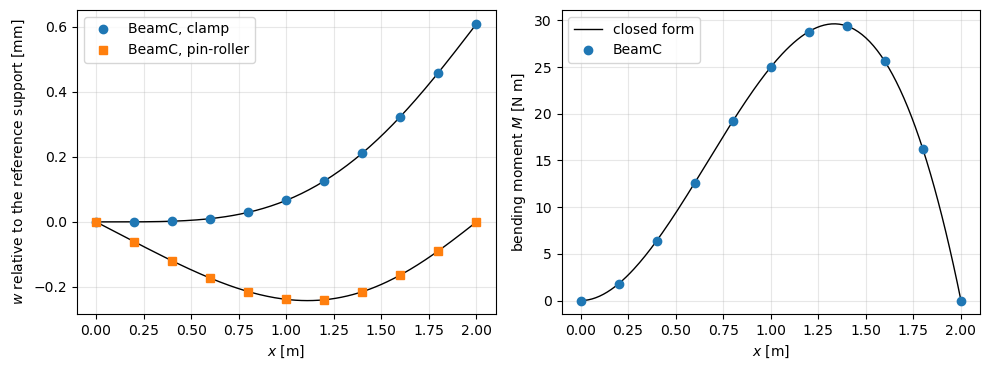

In [12]:
xf = np.linspace(0, L4, 201)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for choice, mk in [('clamp', 'o'), ('pin-roller', 's')]:
    wcf_f, Mcf_f = closed_form(xf, choice)
    axes[0].plot(xf, 1e3*wcf_f, 'k-', lw=1)
    axes[0].plot(xs4, 1e3*res4[choice]['u'][2::DOF], mk, label='BeamC, %s' % choice)
axes[1].plot(xf, closed_form(xf, 'clamp')[1], 'k-', lw=1, label='closed form')
S = beam_end_forces(beams4, prop4, res4['clamp']['u'], M4,
                    -(res4['clamp']['Phi'] @ res4['clamp']['acc']))
axes[1].plot(xs4, np.append(S[:, 4], -S[-1, 10]), 'o', label='BeamC')
axes[0].set_ylabel('$w$ relative to the reference support [mm]')
axes[1].set_ylabel('bending moment $M$ [N m]')
for ax in axes:
    ax.set_xlabel('$x$ [m]')
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

The bar: the same `BeamC` model under an axial force $P = 100$ N at $x = L$,
with the clamp at $x = 0$ as reference support. The nodal displacements match
$u = P x^2/(2 E A L)$ to round-off. The axial force of each element, constant
since $u$ is interpolated linearly, $E A (u_2 - u_1)/L_e$, equals $N$ at the
element midpoint, because the secant slope of a quadratic is its slope at the
midpoint; the end forces recovered as in case 3 give $N$ at the nodes.

In [13]:
fext5 = np.zeros(KC04.shape[0])
fext5[DOF*10] = P4
out = run_inertia_relief(KC04, M4, fext5, reference_dofs(len(xs4), 'clamp'))
EA4 = prop4.E*prop4.A
ucf = P4*xs4**2/(2*EA4*L4)
Ne = EA4*np.diff(out['u'][0::DOF])/(L4/10)
xmid = (xs4[1:] + xs4[:-1])/2
S = beam_end_forces(beams4, prop4, out['u'], M4, -(out['Phi'] @ out['acc']))
print('u_dd = %.6f m/s2, P/(m L) = %.6f m/s2' % (out['acc'][0], P4/(m4*L4)))
print('%6s %14s %14s %10s %10s' % ('x [m]', 'u FE [um]', 'u closed [um]', 'N_e [N]', 'P x_m/L'))
for i, xi in enumerate(xs4):
    row = '%6.2f %14.8f %14.8f' % (xi, 1e6*out['u'][DOF*i], 1e6*ucf[i])
    if i < 10:
        row += ' %10.4f %10.4f' % (Ne[i], P4*xmid[i]/L4)
    print(row)
assert np.isclose(out['acc'][0], P4/(m4*L4), rtol=1e-13)
assert np.allclose(out['u'][0::DOF], ucf, atol=1e-12*ucf.max())
assert np.allclose(Ne, P4*xmid/L4, rtol=1e-11)
assert np.allclose(S[:, 6], P4*xs4[1:]/L4, rtol=1e-11)
print('relative error of u: %.1e' % (abs(out['u'][0::DOF] - ucf).max()/ucf.max()))

u_dd = 6.369427 m/s2, P/(m L) = 6.369427 m/s2
 x [m]      u FE [um]  u closed [um]    N_e [N]    P x_m/L
  0.00     0.00000000     0.00000000     5.0000     5.0000
  0.20     0.00476190     0.00476190    15.0000    15.0000
  0.40     0.01904762     0.01904762    25.0000    25.0000
  0.60     0.04285714     0.04285714    35.0000    35.0000
  0.80     0.07619048     0.07619048    45.0000    45.0000
  1.00     0.11904762     0.11904762    55.0000    55.0000
  1.20     0.17142857     0.17142857    65.0000    65.0000
  1.40     0.23333333     0.23333333    75.0000    75.0000
  1.60     0.30476190     0.30476190    85.0000    85.0000
  1.80     0.38571429     0.38571429    95.0000    95.0000
  2.00     0.47619048     0.47619048
relative error of u: 1.1e-16


Summary
---

- The inertia-relief procedure, built from `KC0` and `M` with the partition
  `bu`/`bk` of pyfe3d, reproduces the closed form of the three-node example,
  its rigid-body acceleration $(F_1 + F_2 + F_3)/(m_1 + m_2 + m_3)$ and its
  displacements, to round-off; with balanced loads, the fictitious support
  alone gives the same solution and no reaction, with unbalanced loads a
  reaction equal to minus the resultant.
- In every case, the loads with the d'Alembert forces satisfy
  $\boldsymbol{\Phi}^\top \boldsymbol{F}_{tot} = \boldsymbol{0}$ and the
  reference support carries no reaction.
- For a balanced load set (case 3), the rigid-body accelerations vanish and
  inertia relief is the fictitious-support solution of the singular static
  problem.
- The displacements depend on the reference support, by a rigid-body motion;
  the spring forces, bending moments and axial forces do not (cases 1, 2 and 3).
- Against the closed forms of the free-free beam and bar (case 4), `BeamC`
  with the consistent mass matrix is exact at the nodes; with the lumped mass
  matrix the deflection converges as $1/n^2$.